# 4.2 · A fundamental factor risk model, after BlackRock's BFRE

> **Needs:** the research cache only.
>
> **Produces:** nothing stored: the model is rebuilt in memory (notebooks 5.2, 5.5 and 5.7 build the same model).

A **factor risk model** estimates how risky a portfolio is and decomposes that risk into its sources. It models each
stock's return as the sum of a few common components - the market, the stock's industry, and its *styles* (size,
value, momentum, volatility, ...) - plus an idiosyncratic component, the **specific** return:

$$r_i = \underbrace{1 \cdot f_{\text{Market}} + 1 \cdot f_{\text{its industry}} + \textstyle\sum_k X_{ik} f_k}_{\text{common}} + u_i$$

The exposures $X$ are observed characteristics of each company on the date (from its statements and price history);
the factor returns $f$ are estimated each day by a cross-sectional regression of stock returns on the exposures. The
covariance matrix of $N$ stocks then follows from the covariance of a couple of dozen factor returns plus one
specific variance per stock, $\Sigma = X F X^\top + D$. Estimating the full $N \times N$ covariance directly is
hopeless: for $N = 1{,}500$ it has over a million distinct entries, and the sample covariance is singular whenever
there are fewer observations than stocks.

This notebook builds such a model from the methodology BlackRock publishes for its **BlackRock Fundamental Risk for
Equities** models (*Aladdin Model Documentation*, September 2025, in `docs/`), and applies it. We follow **BFRE 2.0
Short Horizon** - a one-month forecast that adapts quickly to changes in volatility - on the S&P 1500.

| | BFRE (North America) | Here |
|---|---|---|
| Universe | US and Canada, about 4,000 stocks | the S&P 1500's constituents of each date, 2005-2024 |
| Market factor | every stock has exposure 1 | the same |
| Industries | Refinitiv industries, selected by stepwise tests | the 11 GICS sectors (our vendor gives only the sector for many companies that left the indices) |
| Styles | 14, from 200+ candidate measures | 11 + Mid-Cap, from 35 measures; no analyst-estimate styles (Broker Coverage, Predicted Sales Growth), no foreign sales, no macro betas (Emerging Markets, Oil, VIX) |
| Regression | daily, weighted by the square root of market cap, industry returns constrained to average zero | the same |
| Factor covariance | exponentially weighted (variance half-life 250 days, correlation 500); 2.0: blended with a gamma-scaled copy | the same |
| Specific risk | exponentially weighted (125 days); 2.0: blended with a structural forecast | the same |

The model ends on **31 December 2024**, the last day before the research hold-out, like every notebook here: a risk
model selects no strategy, but its tests are kept to the same years. Building it takes about ten minutes, most of it
loading the universe.

In [1]:
import time
from statistics import NormalDist

import numpy as np
import pandas as pd
from IPython.display import display

from equity_research.analytics.risk import portfolio_risk as pr
from equity_research.analytics.risk import risk_model as rm
from equity_research.analytics.risk.risk_data import load_risk_inputs
from equity_research.analytics.risk.risk_styles import substyles
from equity_research.analytics.screen import tickers
from equity_research.data.cache import ResearchCache
from equity_research.data.universe import load_universe_data
from research_core import charts
from research_core.analytics.risk import statistics as risk_stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
charts.style()
cache = ResearchCache()

UNIVERSE = "SP1500"
START, END = "2005-01-01", "2024-12-31"  # END: the last day before the hold-out
FORECASTS_FROM = "2007-01-01"  # a year of factor returns before the first forecast
ASOF = pd.Timestamp("2024-12-31")  # the day the portfolio examples are measured
EXAMPLES = ["AAPL", "NVDA", "JPM", "XOM", "KO", "TSLA"]

## 1 · Inputs

The universe's daily prices, returns and memberships (as every backtest reads them), plus what the risk model needs
in addition: daily dollar volume, five years of point-in-time accounting items at each month end, and each company's
GICS sector. Sectors are today's: the sector history starts on the day it was first recorded, so a company that
changed sector (Alphabet into Communication Services in 2018) is in its new sector throughout.

In [2]:
started = time.time()
data = load_universe_data(cache, UNIVERSE, START, END, history_days=500)
inputs = load_risk_inputs(cache, data)
print(
    f"{data.returns.shape[1]:,} listings over {len(data.returns):,} days, {len(inputs.dates)} month ends "
    f"({time.time() - started:.0f}s)"
)
display(inputs.industry.value_counts(dropna=False).rename("listings").to_frame().T)

left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


3,384 listings over 5,378 days, 240 month ends (243s)


industry,Information Technology,Financials,Consumer Discretionary,Industrials,Health Care,Energy,Real Estate,Materials,Consumer Staples,Utilities,Communication Services,NaN
listings,539,501,496,494,429,197,190,179,171,101,80,7


## 2 · Exposures: substyles, then styles

Each style is the average of a few **substyles** - alternative measures of one theme - which reduces the measurement
noise of any single one (BFRE 8.2-8.3). All are signed so that a higher value means more of the style:

| Style | Substyles |
|---|---|
| Size | log market cap; log total assets and log sales, each averaged over five years |
| Volatility | beta and residual volatility (five years of weekly returns, half-life one year), their product, the 12-month range of cumulative returns, the volatility of daily returns (half-life 180 days) |
| Momentum | the return over the 11 months ending one month ago; the alpha (intercept) of the beta regression |
| Reversal | the last month's return |
| Liquidity | dollar volume per dollar of market cap over 3, 6 and 12 months; minus the Amihud illiquidity ratio (absolute return per dollar traded) |
| Value | book value, sales and operating cash flow relative to market cap |
| Earnings Yield | earnings relative to market cap; EBIT relative to enterprise value |
| Dividend Yield | trailing 12-month dividends over price |
| Profitability | return on equity and on assets, interest coverage, operating margin, five-year cash flow over current liabilities |
| Growth | the five-year trend in total assets and in sales; the last year's change in assets |
| Leverage | debt over assets, over market cap and over equity; minus cash over assets |
| Mid-Cap | 1 for companies around the 60th size percentile, decaying on either side (BFRE equation 50) |

The coverage of each substyle across constituents: measures needing five years of statements or weekly prices start
in 2007, and operating cash flow arrives with the SEC's XBRL filings (2010 on). A style averages whichever substyles a
stock has; a stock with none is assigned the value predicted by its size and industry.

In [3]:
raw = substyles(inputs)
on_dates = inputs.members.reindex(inputs.dates).fillna(False).astype(bool)
coverage = pd.DataFrame(
    {name: panel.where(on_dates).notna().sum(axis=1) / on_dates.sum(axis=1) for name, panel in raw.items()}
)
yearly = coverage.groupby(coverage.index.year).mean()
display(yearly.loc[[2006, 2008, 2010, 2014, 2019, 2024]].T.style.format("{:.0%}"))

,2006,2008,2010,2014,2019,2024
log_market_value,100%,100%,100%,100%,100%,100%
beta,0%,98%,98%,98%,99%,99%
sigma,0%,98%,98%,98%,99%,99%
beta_sigma,0%,98%,98%,98%,99%,99%
alpha,0%,98%,98%,98%,99%,99%
range_12m,100%,99%,100%,99%,99%,100%
volatility_1y,100%,100%,100%,99%,100%,100%
relative_strength,100%,99%,100%,99%,99%,100%
reversal,100%,100%,100%,100%,100%,100%
turnover_3m,100%,100%,100%,100%,100%,100%


Each substyle is standardised across the day's constituents - mean zero when weighted by the square root of market
cap, standard deviation one, extreme values compressed smoothly towards ±3 - so a style exposure of +1 means one
standard deviation above the average stock. Below: a few companies' exposures at the end of 2024, then the
cross-sectional correlations between styles (BFRE's Figure 3: size is positively correlated with liquidity and
negatively with volatility). High correlations between styles would make the regression's factor returns unstable
(multicollinearity).

In [4]:
exposures = rm.style_exposures(raw, inputs)
styles = list(exposures.styles)
on = exposures.on(ASOF)
names = tickers(cache, on.index)
example = on.assign(ticker=names).set_index("ticker").reindex(EXAMPLES)
display(example[styles].T.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-3, vmax=3))
display(on[styles].corr().style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1))

ticker,AAPL,NVDA,JPM,XOM,KO,TSLA
Size,+2.57,+1.61,+2.41,+2.13,+1.19,+1.64
Volatility,-0.60,+2.40,-0.47,-0.91,-1.43,+2.82
Momentum,+0.20,+2.61,+0.73,-0.03,-0.31,+1.04
Reversal,+1.65,+0.69,+0.24,-0.41,+0.43,+2.81
Liquidity,-0.60,+0.85,-1.29,-0.96,-0.76,+1.99
Value,-0.89,-1.00,-1.29,+0.64,-0.81,-0.98
Earnings Yield,-0.33,-0.48,+0.83,+0.68,-0.19,-0.72
Dividend Yield,-0.62,-0.86,+0.34,+0.86,+0.68,-0.87
Profitability,+2.13,+2.86,-0.72,+0.38,+0.20,+0.19
Growth,-0.48,+2.89,-0.04,+0.61,-0.24,+2.12


,Size,Volatility,Momentum,Reversal,Liquidity,Value,Earnings Yield,Dividend Yield,Profitability,Growth,Leverage,Mid-Cap
Size,+1.00,-0.37,+0.14,+0.08,-0.09,-0.05,+0.10,+0.08,+0.16,-0.06,+0.16,-0.26
Volatility,-0.37,+1.00,-0.02,-0.04,+0.43,+0.12,-0.21,-0.33,-0.25,+0.17,-0.11,+0.10
Momentum,+0.14,-0.02,+1.00,+0.04,-0.36,-0.33,+0.13,-0.04,+0.21,+0.16,-0.12,+0.07
Reversal,+0.08,-0.04,+0.04,+1.00,-0.02,-0.13,-0.12,-0.05,+0.01,-0.06,-0.06,-0.07
Liquidity,-0.09,+0.43,-0.36,-0.02,+1.00,+0.24,-0.03,-0.13,-0.08,+0.06,-0.00,+0.05
Value,-0.05,+0.12,-0.33,-0.13,+0.24,+1.00,+0.21,+0.23,-0.34,-0.18,+0.30,+0.05
Earnings Yield,+0.10,-0.21,+0.13,-0.12,-0.03,+0.21,+1.00,+0.16,+0.48,+0.11,-0.00,+0.05
Dividend Yield,+0.08,-0.33,-0.04,-0.05,-0.13,+0.23,+0.16,+1.00,-0.09,-0.19,+0.32,+0.00
Profitability,+0.16,-0.25,+0.21,+0.01,-0.08,-0.34,+0.48,-0.09,+1.00,+0.20,-0.19,-0.04
Growth,-0.06,+0.17,+0.16,-0.06,+0.06,-0.18,+0.11,-0.19,+0.20,+1.00,-0.22,+0.05


## 3 · Factor returns

Each day, that day's stock returns are regressed cross-sectionally on the exposures of the preceding month end, by
weighted least squares with weights equal to the square root of market cap (a compromise between equal weights, which
let noisy small caps dominate, and cap weights, which let a few mega-caps dominate). The market factor and the full
set of sector dummies are perfectly collinear, so the sectors' weighted-average return is constrained to zero. The
**Market** factor return is then the day's weighted-average return, and each sector's factor return is its return
*in excess of* the market. A style's factor return is the return of a portfolio with unit exposure to that style and
zero exposure to every other factor.

In [5]:
days = pd.DatetimeIndex(data.returns.index)
started = time.time()
model = rm.build_risk_model(data.returns, exposures, list(days[days >= FORECASTS_FROM]))
took = time.time() - started
print(f"{len(model.factor_returns):,} daily regressions, forecasts on {len(model.dates):,} days ({took:.0f}s)")
fr = model.factor_returns.loc[FORECASTS_FROM:]
benchmark = data.benchmark.reindex(fr.index)
print(f"Market factor against the S&P 1500 fund (SPTM), daily: correlation {fr[rm.MARKET].corr(benchmark):.2f}")
summary = rm.factor_summary(fr).loc[[rm.MARKET, *styles]]
display(
    summary.style.format(
        {
            "yearly return": "{:+.1%}",
            "yearly volatility": "{:.1%}",
            "return / volatility": "{:+.2f}",
            "correlation with market": "{:+.2f}",
            "monthly autocorrelation": "{:+.2f}",
        }
    )
)

5,013 daily regressions, forecasts on 4,530 days (31s)
Market factor against the S&P 1500 fund (SPTM), daily: correlation 0.89


,yearly return,yearly volatility,return / volatility,correlation with market,monthly autocorrelation
Market,+12.0%,21.5%,+0.56,+1.00,-0.01
Size,+0.1%,2.9%,+0.04,+0.14,-0.06
Volatility,+0.2%,7.0%,+0.03,+0.77,+0.16
Momentum,+0.6%,5.0%,+0.12,-0.20,+0.03
Reversal,-1.1%,3.5%,-0.31,-0.35,-0.06
Liquidity,+0.4%,2.5%,+0.14,-0.12,-0.15
Value,-0.0%,2.7%,-0.01,-0.01,+0.04
Earnings Yield,-0.2%,2.8%,-0.09,+0.11,-0.09
Dividend Yield,-0.7%,2.3%,-0.30,+0.05,+0.12
Profitability,+0.6%,2.1%,+0.30,-0.08,+0.14


BFRE's Table 2 for comparison (North America, 2000-2024): Market 6.4 % a year at 19.6 % volatility; the styles'
volatilities between 1.7 % and 7.4 %, with Volatility the most correlated with the market (0.79). Below, the
cumulative style factor returns over time:

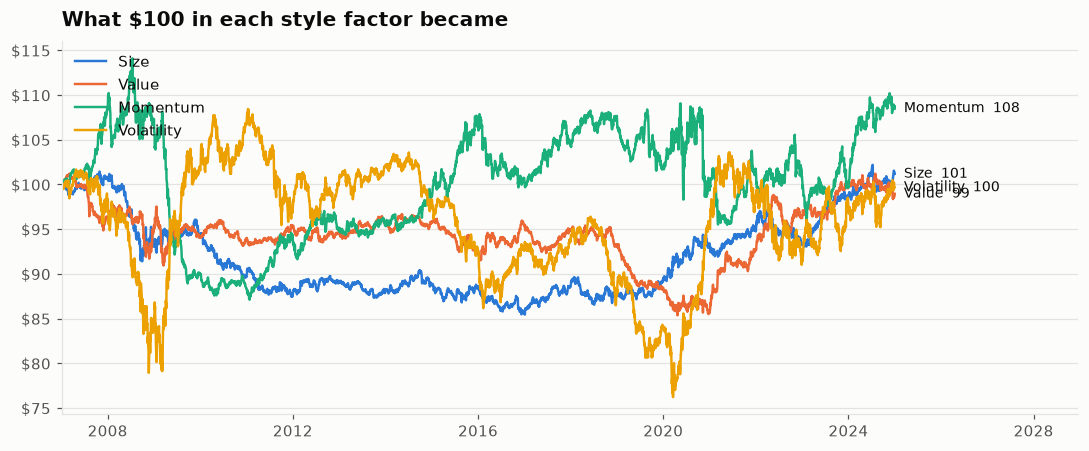

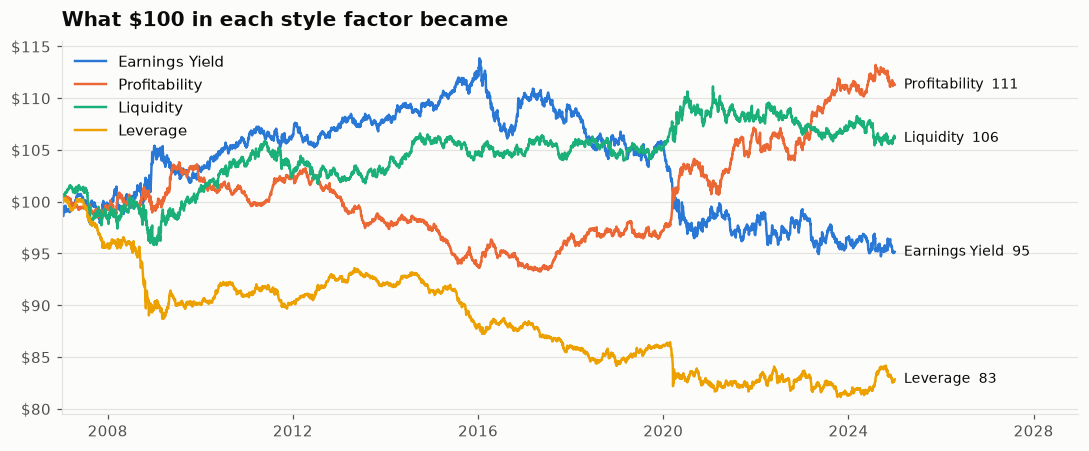

In [6]:
for group in (
    ["Size", "Value", "Momentum", "Volatility"],
    ["Earnings Yield", "Profitability", "Liquidity", "Leverage"],
):
    fig = charts.growth({s: fr[s] for s in group}, "What $100 in each style factor became", log=False)

**Is each factor significant?** BFRE's test: the fraction of days on which a factor's return is statistically
significant ($|t| > 2$). Under the null of no effect it would be about 5 %; BFRE retains a factor above roughly
10 %. Also shown: the fraction of each day's cross-sectional return variance the factors explain (the regression's
$R^2$).

Average daily R²: 22%


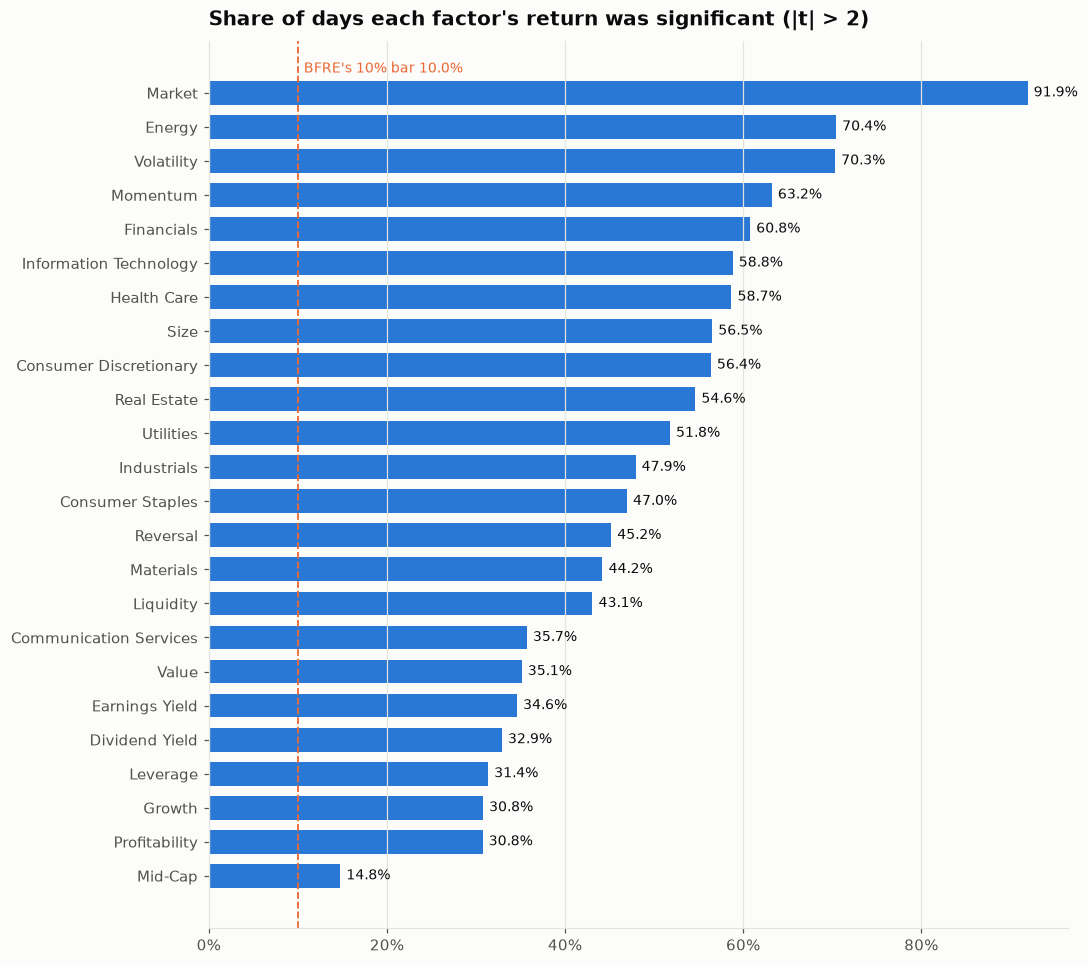

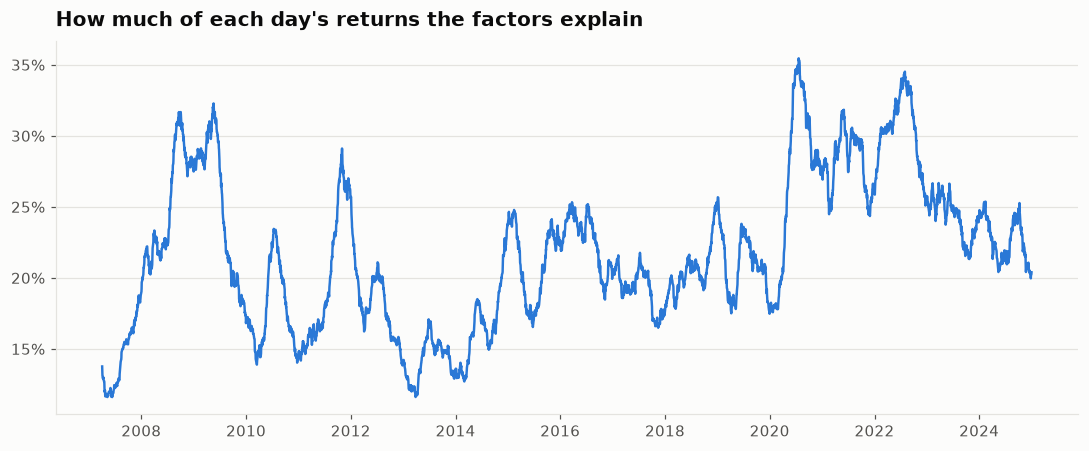

In [7]:
fig = charts.ranked_bars(
    rm.significance(model.tstats.loc[FORECASTS_FROM:]),
    "Share of days each factor's return was significant (|t| > 2)",
    percent=True,
    reference=("BFRE's 10% bar", 0.10),
)
r2 = model.r2.loc[FORECASTS_FROM:]
fig = charts.lines(
    {"R² (three-month average)": r2.rolling(63).mean()},
    "How much of each day's returns the factors explain",
    percent=True,
)
print(f"Average daily R²: {r2.mean():.0%}")

## 4 · Forecasts: 1.0 and 2.0

**BFRE 1.0** forecasts the factor covariance from past factor returns with exponential weights (variance half-life
250 days, correlation half-life 500, with a Newey-West correction for serial correlation when scaling daily to
monthly risk), and each stock's specific volatility from its own specific returns (half-life 125 days; a stock with
a short history is shrunk towards the average of stocks of its size and sector).

**BFRE 2.0** adds a volatility-regime adjustment, **gamma**: the ratio of the last month's realised volatility to its
forecast, pooled across all factors (and, separately, across all stocks' specific returns). The 2.0 factor covariance
is the average of the 1.0 matrix and the 1.0 matrix scaled by gamma²; the 2.0 specific risk is the average of the 1.0
forecast and a *structural* forecast - a regression of next month's realised specific volatility on size,
volatility, liquidity, momentum and the gamma-scaled forecast (BFRE 8.6-8.7). Gamma averages about 1 over long
periods, spikes in crises (2008, 2020) and falls below 1 when markets calm down, so the 2.0 forecast reacts faster to
volatility regimes than exponential weighting alone.

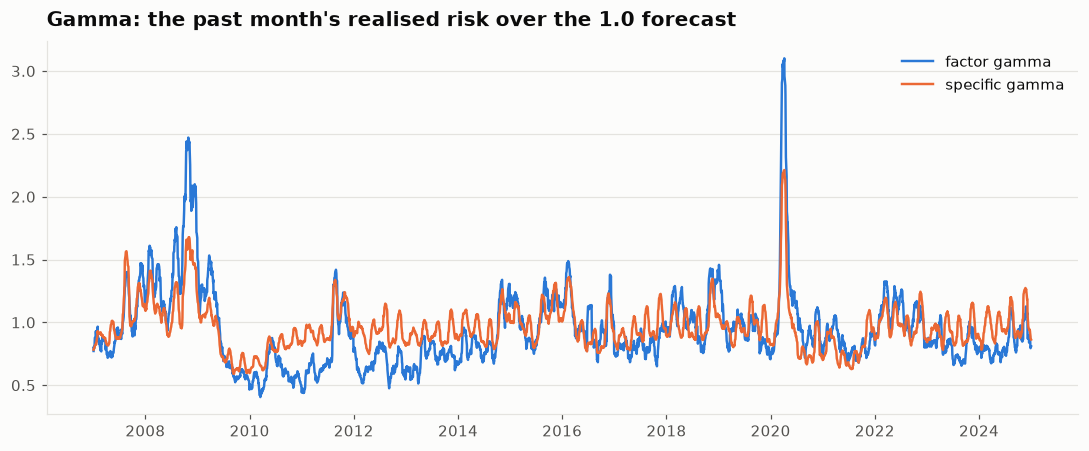

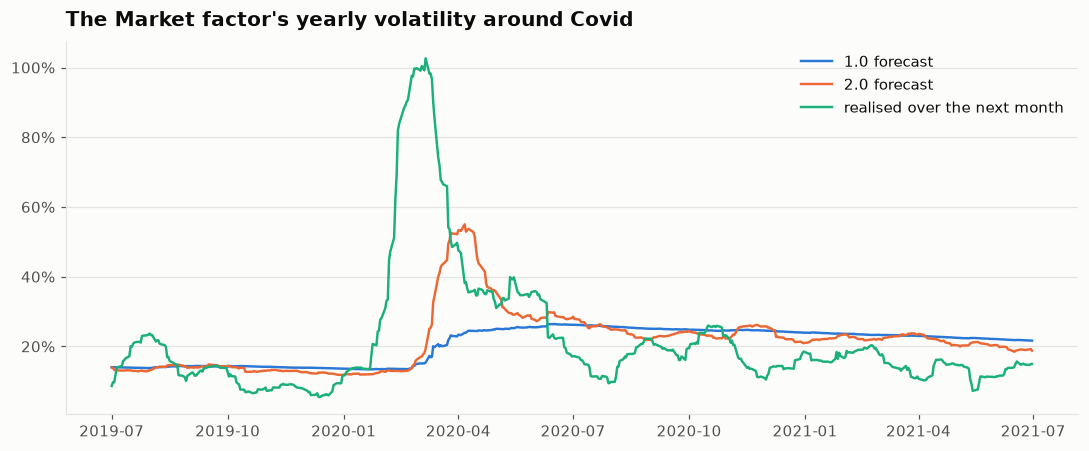

In [8]:
fig = charts.lines(
    {"factor gamma": model.gamma["factor"], "specific gamma": model.gamma["specific"]},
    "Gamma: the past month's realised risk over the 1.0 forecast",
)
market_vol = pd.DataFrame(
    {
        "1.0 forecast": {d: np.sqrt(252 * c.loc[rm.MARKET, rm.MARKET]) for d, c in model.covariance_ewma.items()},
        "2.0 forecast": {d: np.sqrt(252 * c.loc[rm.MARKET, rm.MARKET]) for d, c in model.covariance.items()},
    }
)
squares = (model.factor_returns[rm.MARKET] ** 2).rolling(21).sum()
market_vol["realised over the next month"] = np.sqrt(12 * squares.shift(-21)).reindex(market_vol.index)
window = market_vol.loc["2019-07":"2021-06"]
fig = charts.lines(
    {c: window[c] for c in window.columns}, "The Market factor's yearly volatility around Covid", percent=True
)

## 5 · Forecast evaluation

BFRE's tests (section 5). For a portfolio held for a month, the standardised return $z = r / \hat\sigma$ (return
divided by forecast volatility) should have a standard deviation of one. The **bias statistic** is that standard
deviation; with about 200 monthly observations its sampling error puts the acceptable range at roughly 0.90-1.10
(below: the model over-forecast risk; above: it under-forecast). **Patton's Q-statistic**,
$\text{mean}(z^2 - \ln z^2)$, is a robust loss function for volatility forecasts: it is minimised when the forecast
tracks the true, time-varying volatility, and it penalises under-forecasts more than over-forecasts. Between the two
model versions, the lower Q is better.

Test portfolios: the three indices and the cap-weighted S&P 1500, each sector's constituents, and every constituent
stock individually.

In [9]:
ends = rm.month_ends(days)
ends = ends[ends.isin(model.dates)]
caps = data.market_cap.reindex(ends)
segment = data.segment.reindex(ends)
portfolios = {
    f"S&P {label}": pr.cap_weights(caps, data.members, within=segment == seg)
    for seg, label in (("large", "500"), ("mid", "400"), ("small", "600"))
}
portfolios["S&P 1500"] = pr.cap_weights(caps, data.members)
sector_of = inputs.industry.reindex(caps.columns)
for sector in sorted(sector_of.dropna().unique()):
    portfolios[sector] = pr.cap_weights(caps.loc[:, (sector_of == sector).to_numpy()], data.members)
tests = pr.forecast_tests(model, data.returns, portfolios)
pct = {c: "{:.1%}" for c in ("realised volatility", "forecast 1.0", "forecast 2.0")}
display(tests.style.format(pct | {c: "{:.2f}" for c in ("bias 1.0", "bias 2.0", "Q 1.0", "Q 2.0")}))
print(f"2.0 has the lower Q for {(tests['Q 2.0'] < tests['Q 1.0']).sum()} of {len(tests)} portfolios")
stocks = {v: pr.stock_z_scores(model, data.returns, ends, version=v) for v in ("1.0", "2.0")}
display(
    pd.DataFrame(
        {
            v: {
                "observations": len(z),
                "bias": z.std(),
                "Q": risk_stats.q_statistic(z),
                "beyond ±2.58": (z.abs() > 2.58).mean(),
            }
            for v, z in stocks.items()
        }
    ).T.style.format({"observations": "{:,.0f}", "bias": "{:.2f}", "Q": "{:.2f}", "beyond ±2.58": "{:.1%}"})
)

,realised volatility,forecast 1.0,bias 1.0,Q 1.0,forecast 2.0,bias 2.0,Q 2.0,band
S&P 500,16.6%,18.4%,0.92,2.30,18.0%,0.89,2.19,0.90-1.10
S&P 400,20.1%,20.7%,1.00,2.43,20.1%,0.96,2.29,0.90-1.10
S&P 600,23.4%,23.0%,1.04,2.30,22.4%,1.01,2.18,0.90-1.10
S&P 1500,16.9%,18.6%,0.93,2.37,18.1%,0.90,2.25,0.90-1.10
Communication Services,18.1%,20.3%,0.92,2.32,19.8%,0.93,2.27,0.90-1.10
Consumer Discretionary,21.5%,22.6%,0.93,2.66,22.0%,0.91,2.54,0.90-1.10
Consumer Staples,12.6%,14.4%,0.88,2.34,14.1%,0.88,2.28,0.90-1.10
Energy,27.2%,28.7%,0.95,2.63,28.1%,0.94,2.53,0.90-1.10
Financials,24.0%,25.4%,0.96,2.39,24.8%,0.94,2.29,0.90-1.10
Health Care,16.2%,17.1%,0.97,2.29,16.7%,0.96,2.20,0.90-1.10


2.0 has the lower Q for 15 of 15 portfolios


,observations,bias,Q,beyond ±2.58
1.0,"322,540",1.03,2.59,2.2%
2.0,"322,540",1.04,2.55,2.1%


A normal distribution puts 1 % of outcomes beyond ±2.58 standard deviations; individual stocks' standardised monthly
returns land there more often - their distribution has fatter tails (excess kurtosis) than the normal, which matters
for value at risk below.

## 6 · Applying the model: portfolio risk

An example portfolio: the 30 S&P 500 constituents with the highest **Value** exposure at the end of 2024, equally
weighted, measured on its own (total risk) and relative to the S&P 500 (its **active** risk, or tracking error). The
model also gives its beta to the index: BFRE has no beta factor, so beta follows from the two portfolios' exposures,
$\beta = \frac{w_p^\top \Sigma\, w_b}{w_b^\top \Sigma\, w_b}$.

In [10]:
spx = portfolios["S&P 500"].loc[ASOF].dropna()
cheapest = model.exposures.on(ASOF).loc[spx.index, "Value"].nlargest(30)
book = pd.Series(1 / len(cheapest), index=cheapest.index)
issuers = inputs.listing_issuer
own = pr.portfolio_risk(model, book, ASOF, listing_issuer=issuers)
active = pr.portfolio_risk(model, book, ASOF, benchmark=spx, listing_issuer=issuers)
index_risk = pr.portfolio_risk(model, spx, ASOF, listing_issuer=issuers)
yearly = np.sqrt(12)
display(
    pd.DataFrame(
        {
            "Value book": [own.total * yearly, own.factor * yearly, own.specific * yearly, own.coverage],
            "S&P 500": [
                index_risk.total * yearly,
                index_risk.factor * yearly,
                index_risk.specific * yearly,
                index_risk.coverage,
            ],
            "Value book against the S&P 500": [
                active.total * yearly,
                active.factor * yearly,
                active.specific * yearly,
                active.coverage,
            ],
        },
        index=["risk (yearly volatility)", "from factors", "specific", "weight covered"],
    ).style.format("{:.1%}")
)
print(f"Predicted beta to the S&P 500: {pr.predicted_beta(model, book, spx, ASOF):.2f}")
print("Holdings:", ", ".join(tickers(cache, book.index).dropna().sort_values()))

,Value book,S&P 500,Value book against the S&P 500
risk (yearly volatility),19.3%,15.4%,15.7%
from factors,18.8%,15.1%,14.9%
specific,4.3%,2.7%,5.0%
weight covered,100.0%,100.0%,100.0%


Predicted beta to the S&P 500: 0.77
Holdings: ADM, APA, BG, BWA, CE, CNC, COF, CVS, DG, DLTR, DVN, EG, F, GM, IVZ, MET, MGM, MHK, MOS, MPC, PRU, PSX, SKYD, SYF, TAP, TSN, VLO, VTRS, WBA, WBD


Risk attribution of the active portfolio. A factor's **contribution** is its exposure times its covariance with the
whole active portfolio, divided by the portfolio's volatility (an Euler decomposition): contributions sum exactly to
the tracking error, and a large exposure to a factor that is negatively correlated with the others can even reduce
total risk. First by block (market, sectors, styles, specific), then the largest individual factors.

,exposure,contribution,share of risk
Value,+2.66,+4.36%,28%
Momentum,-1.27,+3.38%,22%
Specific,,+1.61%,10%
Profitability,-1.57,+1.22%,8%
Information Technology,-0.31,+1.06%,7%
Size,-0.91,+0.90%,6%
Earnings Yield,+0.62,+0.88%,6%
Energy,+0.13,+0.66%,4%
Dividend Yield,+0.69,+0.49%,3%
Growth,-0.61,+0.48%,3%


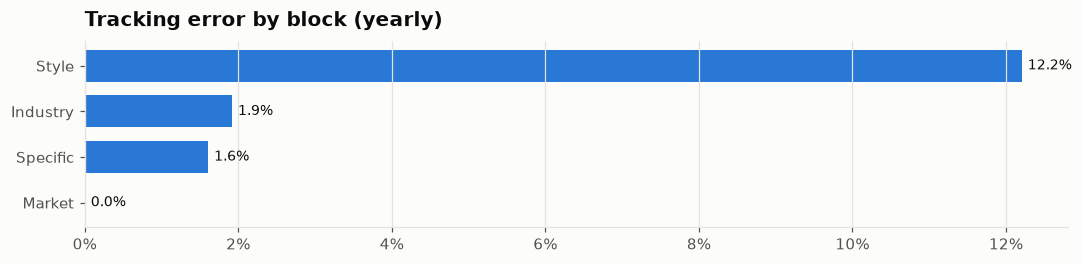

In [11]:
blocks = pr.by_block(active, model) * yearly
fig = charts.ranked_bars(blocks, "Tracking error by block (yearly)", percent=True)
table = pr.risk_table(active)
top = table["contribution"].abs().sort_values(ascending=False).index[:10]
display(
    table.loc[top]
    .assign(contribution=lambda t: t["contribution"] * yearly)
    .style.format({"exposure": "{:+.2f}", "contribution": "{:+.2%}", "share of risk": "{:.0%}"}, na_rep="")
)

## 7 · Parametric value at risk

**Value at risk** is the loss a portfolio should not exceed with a given confidence over a given horizon - a quantile
of its return distribution. The parametric (variance-covariance) version takes the model's volatility $\sigma$ and
assumes returns are normal with mean zero: $\text{VaR}_c = z_c\,\sigma$, with $z_{99\%} = 2.33$. Because volatility
decomposes exactly into factor and specific contributions, so does VaR: each factor's **component VaR** is its share
of the total. On a $10 million portfolio:

,Value book,against the S&P 500
"1 day, 95%","$200,055","$162,962"
"1 day, 99%","$282,942","$230,480"
"1 month, 99%","$1,296,603","$1,056,194"


One-day 99% VaR: $282,942, of which Market $181,724, Industry $1,421, Style $85,989, Specific $13,807


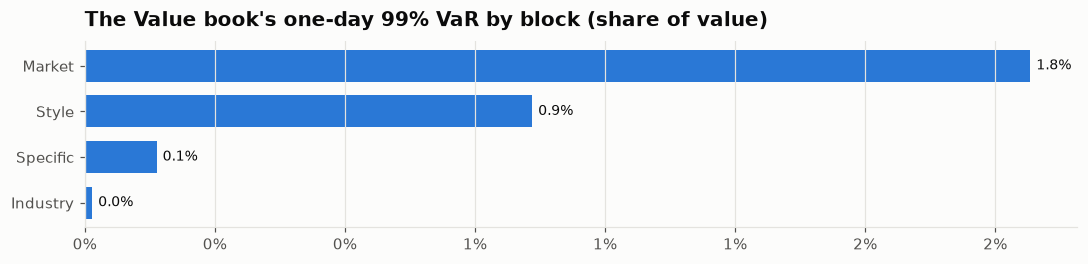

In [12]:
VALUE = 10_000_000
rows = {}
for label, horizon, confidence in (("1 day, 95%", 1, 0.95), ("1 day, 99%", 1, 0.99), ("1 month, 99%", 21, 0.99)):
    row = {}
    for name, bench in (("Value book", None), ("against the S&P 500", spx)):
        risk = pr.portfolio_risk(model, book, ASOF, horizon=horizon, benchmark=bench, listing_issuer=issuers)
        row[name] = pr.value_at_risk(risk, confidence)["Total"] * VALUE
    rows[label] = row
display(pd.DataFrame(rows).T.style.format("${:,.0f}"))

day = pr.portfolio_risk(model, book, ASOF, horizon=1, listing_issuer=issuers)
z99 = pr.value_at_risk(day, 0.99)["Total"] / day.total
component = pr.by_block(day, model) * z99 * VALUE
fig = charts.ranked_bars(component / VALUE, "The Value book's one-day 99% VaR by block (share of value)", percent=True)
print(
    f"One-day 99% VaR: ${pr.value_at_risk(day, 0.99)['Total'] * VALUE:,.0f}, of which "
    + ", ".join(f"{k} ${v:,.0f}" for k, v in component.items())
)

**Backtesting the VaR.** A 99 % one-day VaR should be exceeded on about 1 day in 100. BFRE's surveillance counts the
exceptions and applies **Kupiec's proportion-of-failures test**, a likelihood-ratio test of whether the observed
exception rate equals the promised 1 %: a p-value below 5 % rejects the VaR. Each index is tested, weighted as at
the latest month end, every day from 2007 to 2024. Then the diagnosis: each day's return divided by its forecast
volatility. A standard deviation of one means the volatility forecast was right; a 1 % quantile below the normal's
-2.33 means the tails are fatter than the normality assumption allows.

,days,exceptions,expected,rate,kupiec_lr,p_value
S&P 500 1.0,"4,510",111,45,2.46%,69.1,0.000
S&P 500 2.0,"4,510",100,45,2.22%,50.1,0.000
S&P 400 1.0,"4,510",101,45,2.24%,51.8,0.000
S&P 400 2.0,"4,510",90,45,2.00%,35.0,0.000
S&P 600 1.0,"4,510",88,45,1.95%,32.3,0.000
S&P 600 2.0,"4,510",70,45,1.55%,11.9,0.001


,standard deviation,1% quantile,normal's 1% quantile
S&P 500 1.0,+1.08,-3.29,-2.33
S&P 500 2.0,+0.99,-2.93,-2.33
S&P 400 1.0,+1.07,-3.06,-2.33
S&P 400 2.0,+0.99,-2.73,-2.33
S&P 600 1.0,+1.08,-2.91,-2.33
S&P 600 2.0,+1.01,-2.70,-2.33


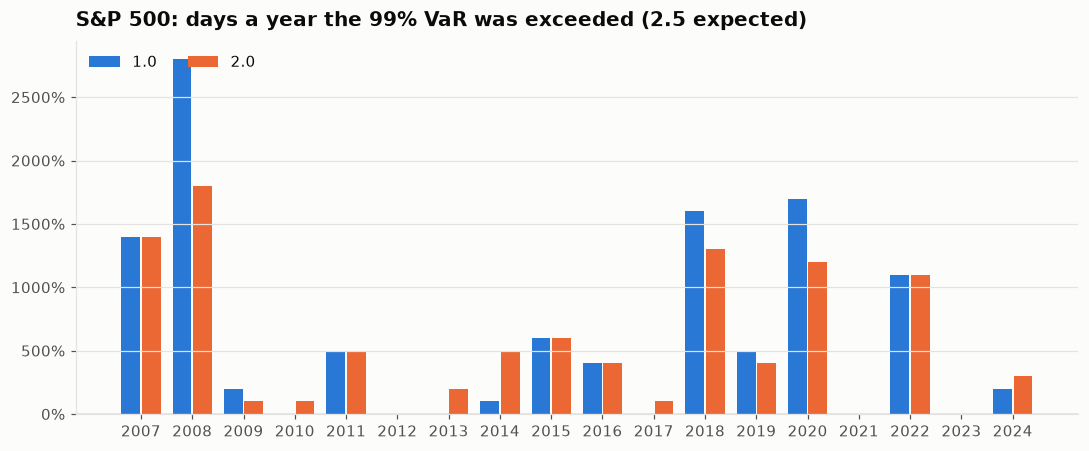

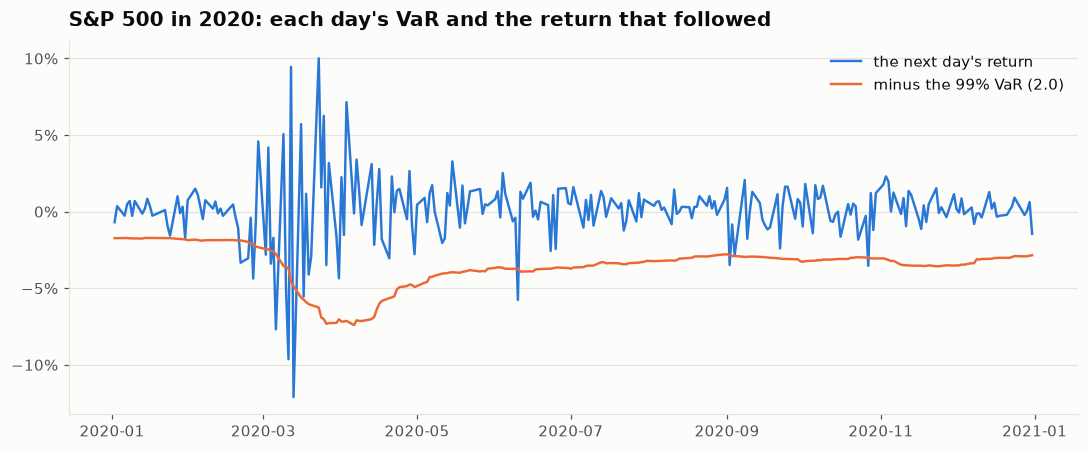

In [13]:
backtests = {
    f"{name} {version}": pr.var_backtest(model, portfolios[name], data.returns, version=version)
    for name in ("S&P 500", "S&P 400", "S&P 600")
    for version in ("1.0", "2.0")
}
display(
    risk_stats.kupiec_summary(backtests).style.format(
        {
            "days": "{:,.0f}",
            "exceptions": "{:,.0f}",
            "expected": "{:,.0f}",
            "rate": "{:.2%}",
            "kupiec_lr": "{:.1f}",
            "p_value": "{:.3f}",
        }
    )
)
by_year = pd.DataFrame(
    {v: backtests[f"S&P 500 {v}"]["exception"].groupby(lambda d: d.year).sum() for v in ("1.0", "2.0")}
)
fig = charts.yearly_bars(by_year, "S&P 500: days a year the 99% VaR was exceeded (2.5 expected)")
z99 = NormalDist().inv_cdf(0.99)
tails = {}
for name, bt in backtests.items():
    z = bt["realised"] / (bt["var"] / z99)  # each day's return over its forecast volatility
    tails[name] = {"standard deviation": z.std(), "1% quantile": z.quantile(0.01), "normal's 1% quantile": -z99}
display(pd.DataFrame(tails).T.style.format("{:+.2f}"))
crisis = backtests["S&P 500 2.0"].loc["2020-01":"2020-12"]
fig = charts.lines(
    {"the next day's return": crisis["realised"], "minus the 99% VaR (2.0)": -crisis["var"]},
    "S&P 500 in 2020: each day's VaR and the return that followed",
    percent=True,
)

## 8 · Stress tests: shock a factor, read the P&L

A stress test asks what a portfolio would gain or lose if a factor made a given move - the Market down 10 %, Value
down three standard deviations in a month. The P&L is the exposure times the move, computed two ways:

* **Isolated** - only the shocked factor moves; every other factor return is set to zero. This is the P&L of the bet
  on that factor alone: a portfolio with no Value exposure loses nothing in a Value crash.
* **Correlated** - the other factors move by their expected value conditional on the shock, under the model's
  covariance, $E[f_{\text{other}} \mid f_{\text{shocked}} = s] = F_{os} F_{ss}^{-1} s$ (the conditional mean of
  jointly normal returns). A market fall then also pulls down Volatility (high-volatility stocks fall more) and moves
  the sectors that usually co-move with the market, so a portfolio's beta shows up here but not in the isolated
  number.

Specific returns are set to their expected value of zero in both. Edit `SCENARIOS` to define your own: a shock is a
factor return (`-0.10`), or a number of the factor's monthly standard deviations via `pr.shock_in_sigmas`. Several
factors shocked together form one joint scenario.

In [14]:
SCENARIOS = {
    "Market -10%": {rm.MARKET: -0.10},
    "Value -3 sd in a month": pr.shock_in_sigmas(model, ASOF, {"Value": -3.0}),
    "Momentum -4 sd in a month": pr.shock_in_sigmas(model, ASOF, {"Momentum": -4.0}),
    "Energy -15% against the market": {"Energy": -0.15},
    "Market -10% and Volatility -3 sd": {rm.MARKET: -0.10} | pr.shock_in_sigmas(model, ASOF, {"Volatility": -3.0}),
}
rows = {}
for scenario, shocks in SCENARIOS.items():
    own_book = pr.stress_test(model, book, ASOF, shocks)
    against = pr.stress_test(model, book, ASOF, shocks, benchmark=spx)
    rows[scenario] = {
        "shock": ", ".join(f"{k} {v:+.1%}" for k, v in shocks.items()),
        "book, isolated": own_book.isolated * VALUE,
        "book, with correlations": own_book.correlated * VALUE,
        "against S&P 500, isolated": against.isolated * VALUE,
        "against S&P 500, with correlations": against.correlated * VALUE,
    }
money = "${:,.0f}"
display(
    pd.DataFrame.from_dict(rows, orient="index")
    .style.format({c: money for c in list(rows[scenario])[1:]})
    .set_caption(f"P&L of the $10 million Value book on {ASOF:%d %B %Y}")
)

,shock,"book, isolated","book, with correlations","against S&P 500, isolated","against S&P 500, with correlations"
Market -10%,Market -10.0%,"$-1,000,000","$-1,074,177",$0,"$-153,028"
Value -3 sd in a month,Value -2.3%,"$-515,035","$-575,848","$-620,076","$-829,185"
Momentum -4 sd in a month,Momentum -5.8%,"$538,937","$1,130,063","$736,142","$963,291"
Energy -15% against the market,Energy -15.0%,"$-250,000","$-266,791","$-201,932","$-388,651"
Market -10% and Volatility -3 sd,"Market -10.0%, Volatility -5.3%","$-1,060,644","$-1,090,441","$-118,084","$-118,114"


**One scenario, factor by factor.** The Market falling 10 %: isolated, the portfolio loses exactly its market exposure
(1) times 10 %. Correlated, the factors that usually co-move with the market move too: Momentum tends to *rise* when
the market falls (the previous year's losers, typically high-beta, fall hardest), which costs a portfolio with
negative momentum exposure; defensive sectors such as consumer staples gain relative to the market. The table
attributes each version's P&L to factors; the bars show the largest components of the correlated one.

The correlated P&L divided by the shock is the portfolio's beta to the **Market factor**, not to the S&P 500: the
Market factor weights stocks by the square root of market cap, so the S&P 500 itself does not fall the full 10 % in
this scenario (shown on the last line). The 0.76 beta to the S&P 500 in section 6 is a different quantity again: it
also reflects the variance of factors that move independently of the market.

,exposure,isolated move,isolated P&L,correlated move,correlated P&L
Market,+1.00,-10.00%,"$-1,000,000",-10.00%,"$-1,000,000"
Momentum,-0.93,+0.00%,$-0,+0.92%,"$-85,918"
Consumer Staples,+0.23,+0.00%,$0,+2.24%,"$52,254"
Volatility,+0.11,+0.00%,$0,-2.91%,"$-33,401"
Earnings Yield,+0.50,+0.00%,$0,-0.39%,"$-19,627"
Liquidity,+0.89,+0.00%,$0,+0.21%,"$19,190"
Financials,+0.20,+0.00%,$0,-0.96%,"$-19,109"
Health Care,+0.10,+0.00%,$0,+1.63%,"$16,270"
Profitability,-0.88,+0.00%,$-0,+0.10%,"$-8,654"
Communication Services,+0.07,+0.00%,$0,+1.21%,"$8,049"


Market -10%: the book -10.0% isolated, -10.7% with correlations; the S&P 500 -9.2% with correlations


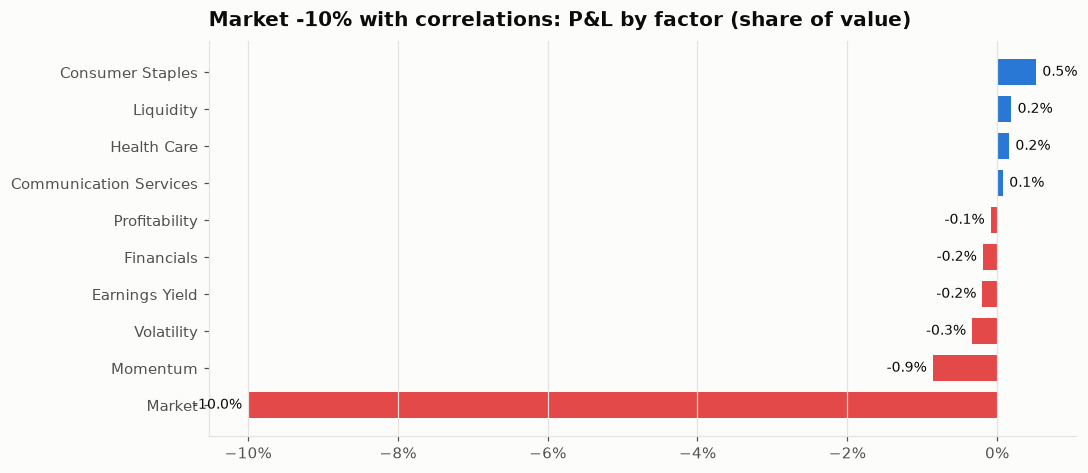

In [15]:
market_fall = pr.stress_test(model, book, ASOF, SCENARIOS["Market -10%"])
detail = market_fall.table.assign(
    **{"isolated P&L": lambda t: t["isolated P&L"] * VALUE, "correlated P&L": lambda t: t["correlated P&L"] * VALUE}
)
largest = detail["correlated P&L"].abs().sort_values(ascending=False).index[:10]
display(
    detail.loc[largest].style.format(
        {
            "exposure": "{:+.2f}",
            "isolated move": "{:+.2%}",
            "isolated P&L": money,
            "correlated move": "{:+.2%}",
            "correlated P&L": money,
        }
    )
)
index_fall = pr.stress_test(model, spx, ASOF, SCENARIOS["Market -10%"]).correlated
print(
    f"Market -10%: the book {market_fall.isolated:+.1%} isolated, {market_fall.correlated:+.1%} with correlations; "
    f"the S&P 500 {index_fall:+.1%} with correlations"
)
fig = charts.ranked_bars(
    detail.loc[largest, "correlated P&L"] / VALUE,
    "Market -10% with correlations: P&L by factor (share of value)",
    percent=True,
)

## Findings

* **The factors explain about a fifth of the daily cross-section of returns** - an average $R^2$ of 22 %, nearer 30 %
  in the stressed years 2020-2022 (correlations rise in crises) - and every factor clears BFRE's significance bar:
  the Market factor is significant on 92 % of days, Volatility and Momentum on about two-thirds, the weakest
  (Mid-Cap) on 15 %. The Market factor's daily correlation with the S&P 1500 ETF is 0.89 (it weights by the square
  root of market cap, so mid and small caps count more than in the index).
* **The styles earned little premium in 2007-2024.** Value earned nothing, Momentum 0.6 % a year, Profitability
  0.6 % (the best return-to-risk ratio, 0.30); highly levered and high-dividend stocks lagged (-1.1 % and -0.7 %).
  Each style's volatility is small next to the market's - 1.7 % to 7 % a year against 21.5 % - and Volatility is the
  most market-like style (correlation 0.77; BFRE reports 0.79).
* **The volatility forecasts are approximately unbiased, erring high for the least volatile portfolios.** The S&P 400
  and 600 fall inside the band (bias statistics of 0.96 and 1.01 for 2.0); the S&P 500 was forecast at 17.9 %
  against 16.6 % realised (bias 0.89), and consumer staples, utilities and real estate are over-forecast the most.
  Individual stocks, pooled, give 1.04.
* **BFRE 2.0 beats 1.0**, as the paper reports: a lower Q-statistic for all 15 test portfolios. Gamma peaked at 3.1
  in April 2020 and stays between 0.75 and 1 in most calm years.
* **Parametric VaR gets the scale of risk right but not the shape of the distribution.** Daily returns divided by
  their 2.0 forecast have a standard deviation of 0.99-1.01, yet the 99 % one-day VaR was exceeded on 2.2 % of days
  for the S&P 500 and 1.6 % for the S&P 600, not 1 %; Kupiec's test rejects every index. The exceptions cluster in
  2007-2008, 2018, 2020 and 2022, and the standardised returns' 1 % quantile is near -2.9, not the normal's -2.33. A
  fat-tailed quantile multiplier (Cornish-Fisher expansion, or a Student-t fitted to these quantiles) is the fix; the
  volatility forecast itself needs none.
* **Stress tests show what correlations add.** A 10 % Market fall costs the Value portfolio $1.00 million isolated and
  $1.07 million correlated - mostly because momentum tends to rise when the market falls, and the portfolio has
  negative momentum exposure. Relative to the S&P 500 the same shock is zero isolated (both have a market exposure of
  one) but -$153,000 correlated. A four-standard-deviation Momentum crash (-5.8 % in a month) earns the portfolio
  $0.54 million isolated and $1.13 million correlated (cheap stocks tend to rally when momentum crashes); a
  three-standard-deviation Value fall (-2.3 %) costs $0.52 million isolated, $0.58 million correlated.
* **In application**, the 30 cheapest S&P 500 constituents at the end of 2024 have 19 % annual volatility, a beta of
  0.77 and a 15.7 % tracking error against the index - most of it the intended Value bet (28 %), then the negative
  momentum exposure that comes with cheap stocks (22 %); stock-specific risk is only a tenth. Its one-day 99 % VaR on
  $10 million is about $280,000, two-thirds of it from the market factor.

**Limitations.** Industries are today's GICS sectors applied to the past (no finer level: the vendor has only sectors
for many deleted constituents); no analyst-estimate, foreign-sales or macro styles; statements before 2009 are LSEG's
latest restated figures; the specific returns of two share classes of one company are treated as one only when a
portfolio's risk is measured (``listing_issuer``), not in the forecasts. Worthwhile next steps: a fat-tailed VaR,
BFRE's stepwise selection of styles (equations 3-6) instead of our fixed list, and industry groups once deleted
constituents are classified.

## Glossary

* **Exposure** - a stock's loading on a factor: 1 for the market and for its own sector; for a style, its
  standardised score (standard deviations above the average stock).
* **Factor return** - the day's return of a portfolio with unit exposure to the factor and zero to all others,
  estimated by cross-sectional regression.
* **Specific return / risk** - the residual of a stock's return after the factors, and its volatility.
* **Estimation universe** - the stocks the regressions are fitted on: the day's constituents with a market cap and a
  sector.
* **Half-life** - in exponential weighting, the age at which an observation receives half the weight of today's.
* **Newey-West** - a correction for serial correlation in daily returns when scaling daily risk up to a monthly
  horizon.
* **Gamma** - the ratio of the last month's realised volatility to the forecast; BFRE 2.0 adjusts the forecast
  towards it.
* **Bias statistic, Q-statistic** - see section 5. **Tracking error** - the volatility of a portfolio's return minus
  its benchmark's.
* **Value at risk (VaR)**, **component VaR**, **Kupiec test** - see section 7.
* **Stress test** - a portfolio's P&L if a factor makes a given move; **isolated** (only that factor moves) or
  **correlated** (the others move by their conditional expectation given the shock) - see section 8.